tensor([[-8.4134,  6.9352],
        [-5.7665, -6.4312],
        [-6.0421, -6.7661],
        ...,
        [ 3.2158,  5.9217],
        [-7.7939, -7.1606],
        [-9.6816,  7.0097]])

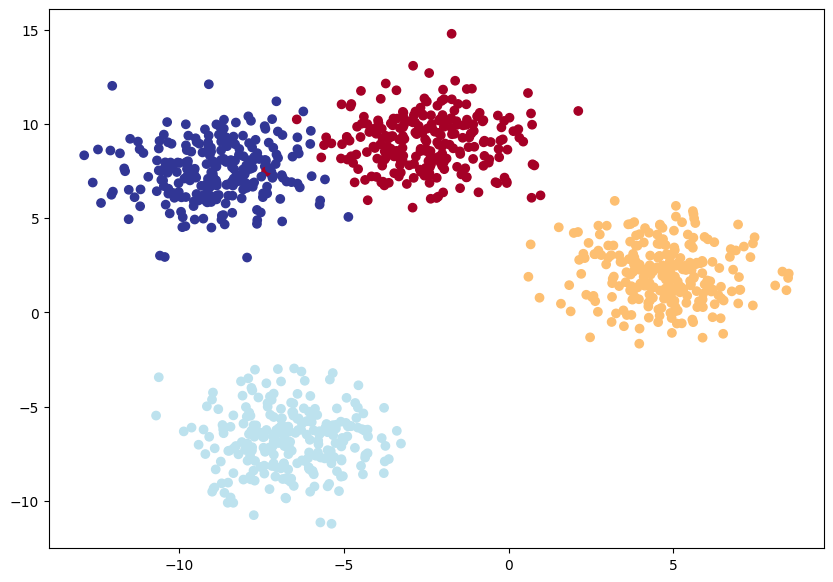

In [214]:
from torch import nn
import torch
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split
from torch._C import dtype

from helper_functions import plot_decision_boundary

NUM_CLASSES = 4
NUM_FEATURES = 2
RANDOM_SEED = 42

X_blob, y_blob = make_blobs(n_samples=1000,
                            n_features=NUM_FEATURES,
                            centers=NUM_CLASSES,
                            cluster_std=1.5,
                            random_state=RANDOM_SEED)

X_blob = torch.from_numpy(X_blob).type(torch.float)
y_blob = torch.from_numpy(y_blob).type(torch.LongTensor)

X_blob_train, X_blob_test, y_blob_train, y_blob_test = train_test_split(X_blob, y_blob,
                                                                        test_size=0.2,
                                                                        random_state=RANDOM_SEED)

# Plot data

plt.figure(figsize=(10, 7))
plt.scatter(X_blob[:, 0], X_blob[:, 1], c=y_blob, cmap=plt.cm.RdYlBu)
X_blob

In [215]:
device = "cuda" if torch.cuda.is_available() else "cpu"

In [216]:
class BlobModelV0(nn.Module):
    def __init__(self, input_features, output_features, hidden_units=8) -> None:
        super().__init__()
        self.linear_layer_stack = nn.Sequential(nn.Linear(in_features=input_features, out_features=hidden_units),
                                                nn.Linear(in_features=hidden_units, out_features=hidden_units),
                                                nn.Linear(in_features=hidden_units, out_features=output_features))

    def forward(self, X):
        return self.linear_layer_stack(X)

torch.manual_seed(42)
model = BlobModelV0(input_features=2, output_features=4).to(device)

In [217]:
model.eval()
with torch.inference_mode():
    y_initial_logits = model(X_blob)
    y_initial_prods = torch.softmax(y_initial_logits, 1)

y_initial_prods, y_initial_logits

(tensor([[0.2836, 0.0134, 0.2918, 0.4112],
         [0.3382, 0.0803, 0.4622, 0.1193],
         [0.3390, 0.0768, 0.4705, 0.1136],
         ...,
         [0.2016, 0.1963, 0.1607, 0.4414],
         [0.3439, 0.0513, 0.5031, 0.1017],
         [0.2879, 0.0098, 0.3049, 0.3974]]),
 tensor([[ 1.8160, -1.2375,  1.8446,  2.1876],
         [ 2.0216,  0.5831,  2.3340,  0.9794],
         [ 2.1112,  0.6262,  2.4390,  1.0179],
         ...,
         [-0.9888, -1.0151, -1.2155, -0.2049],
         [ 2.5688,  0.6664,  2.9493,  1.3507],
         [ 2.1242, -1.2569,  2.1816,  2.4467]]))

In [218]:
y_preds = torch.argmax(y_initial_prods, dim = 1)
y_preds

tensor([3, 2, 2, 1, 1, 2, 1, 2, 2, 1, 1, 3, 3, 2, 2, 2, 3, 3, 3, 1, 1, 3, 3, 3,
        1, 3, 3, 3, 2, 1, 2, 2, 2, 3, 3, 3, 2, 3, 3, 3, 1, 2, 1, 3, 1, 3, 3, 1,
        3, 1, 2, 3, 1, 3, 3, 3, 3, 3, 3, 2, 2, 3, 2, 3, 3, 3, 2, 2, 1, 3, 3, 3,
        1, 2, 1, 3, 3, 3, 3, 3, 2, 3, 3, 3, 1, 3, 2, 2, 3, 3, 3, 3, 1, 1, 3, 3,
        3, 3, 3, 2, 1, 3, 2, 3, 3, 3, 1, 3, 2, 3, 3, 2, 3, 1, 1, 1, 2, 3, 2, 1,
        3, 2, 3, 1, 3, 2, 3, 3, 2, 3, 3, 2, 1, 3, 1, 3, 3, 2, 1, 1, 3, 3, 3, 3,
        3, 1, 3, 3, 3, 3, 3, 3, 2, 2, 3, 1, 3, 1, 1, 3, 2, 3, 3, 2, 3, 3, 1, 2,
        3, 2, 3, 3, 3, 1, 3, 3, 2, 3, 2, 3, 3, 1, 3, 2, 3, 2, 1, 3, 3, 2, 1, 3,
        3, 3, 3, 3, 2, 2, 2, 3, 3, 2, 3, 3, 1, 3, 2, 3, 1, 2, 2, 3, 2, 2, 3, 3,
        2, 3, 3, 1, 3, 3, 2, 3, 3, 3, 1, 2, 2, 3, 3, 2, 3, 3, 2, 2, 3, 2, 2, 1,
        2, 2, 2, 1, 3, 3, 3, 3, 1, 1, 3, 1, 3, 1, 1, 2, 3, 2, 2, 1, 1, 3, 2, 1,
        3, 3, 2, 1, 3, 3, 1, 3, 3, 2, 3, 3, 1, 3, 2, 3, 3, 2, 3, 1, 2, 3, 3, 2,
        3, 3, 3, 3, 2, 2, 2, 3, 2, 2, 2,

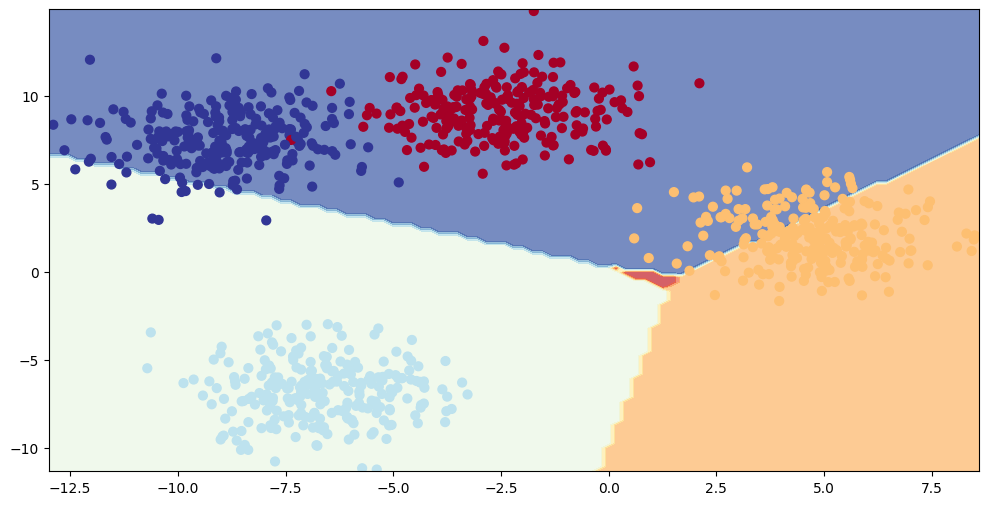

In [219]:
plt.figure(figsize = (12,6))
plot_decision_boundary(model, X_blob, y_blob)

In [220]:
optimizer = torch.optim.SGD(lr = 0.1,
                            params = model.parameters())

loss_fn = nn.CrossEntropyLoss()

In [221]:
def accuracy_fn(y_true, y_labels):
    correct = torch.eq(y_labels, y_true).sum().item()
    acc = correct / len(y_true) * 100
    return acc

In [222]:
torch.manual_seed(42)

In [223]:
epochs = 10000

epoch_count = []
loss_values = []
test_loss_values = []

for epoch in range(epochs):
    model.train()

    y_logits = model(X_blob_train)
    y_probs = torch.softmax(y_logits, 1)
    y_preds = torch.argmax(y_probs, 1)

    loss = loss_fn(y_logits, y_blob_train)
    acc = accuracy_fn(y_blob_train, y_preds)

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()


    model.eval()
    with torch.inference_mode():
        y_test_logits = model(X_blob_test)
        y_test_probs = torch.softmax(y_test_logits, 1)
        y_test_preds = torch.argmax(y_test_probs, 1)

        test_loss = loss_fn(y_test_logits, y_blob_test)
        test_acc = accuracy_fn(y_blob_test, y_test_preds)

    if epoch % 50 == 0:
        epoch_count.append(epoch)
        loss_values.append(loss)
        test_loss_values.append(test_loss)

        print(f"Epoch {epoch} ! Loss = {loss} ! Acc : {acc} ! Test Loss = {test_loss} ! Test Acc : {test_acc}")

Epoch 0 ! Loss = 1.0432370901107788 ! Acc : 65.5 ! Test Loss = 0.5786145925521851 ! Test Acc : 95.5
Epoch 50 ! Loss = 0.04294963181018829 ! Acc : 99.0 ! Test Loss = 0.034860678017139435 ! Test Acc : 99.5
Epoch 100 ! Loss = 0.03184868022799492 ! Acc : 99.125 ! Test Loss = 0.022926390171051025 ! Test Acc : 99.5
Epoch 150 ! Loss = 0.028572537004947662 ! Acc : 99.125 ! Test Loss = 0.019015701487660408 ! Test Acc : 99.5
Epoch 200 ! Loss = 0.027066180482506752 ! Acc : 99.125 ! Test Loss = 0.017038214951753616 ! Test Acc : 99.5
Epoch 250 ! Loss = 0.026207029819488525 ! Acc : 99.25 ! Test Loss = 0.015823960304260254 ! Test Acc : 99.5
Epoch 300 ! Loss = 0.025644611567258835 ! Acc : 99.25 ! Test Loss = 0.014989900402724743 ! Test Acc : 99.5
Epoch 350 ! Loss = 0.025238454341888428 ! Acc : 99.25 ! Test Loss = 0.01437320839613676 ! Test Acc : 99.5
Epoch 400 ! Loss = 0.024923035874962807 ! Acc : 99.25 ! Test Loss = 0.013892659917473793 ! Test Acc : 99.5
Epoch 450 ! Loss = 0.02466445416212082 ! Acc :

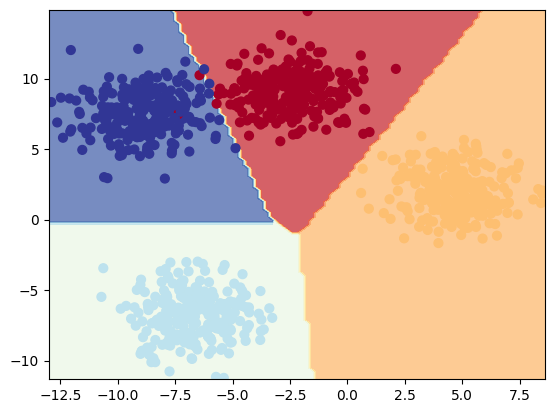

In [225]:
plot_decision_boundary(model, X_blob, y_blob)